# Compare countries

Load the same indicator for several countries into one DataFrame. The free trial covers
USA, CHN, DEU, JPN, GBR, FRA, IND, BRA, RUS and KOR.

In [1]:
%pip install -q econdash pandas matplotlib


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd

from econdash import EconDash

ed = EconDash()
countries = ["USA", "CHN", "DEU", "JPN", "IND"]
frames = {
    c: pd.Series(
        {p.date: p.value for p in ed.get_series("gdp-growth-annual-percent", c, start=2000).data}
    )
    for c in countries
}
growth = pd.DataFrame(frames)
growth.tail()

,USA,CHN,DEU,JPN,IND
2021-01-01,6.152022,8.570384,3.910000,3.564195,9.689592
2022-01-01,2.524214,3.133854,1.809258,1.331648,7.609365
2023-01-01,2.934363,5.416003,-0.869648,0.720785,7.210225
2024-01-01,2.793187,4.958304,-0.495852,-0.240084,7.099279
2025-01-01,2.161382,4.959949,0.239578,1.193113,7.566662


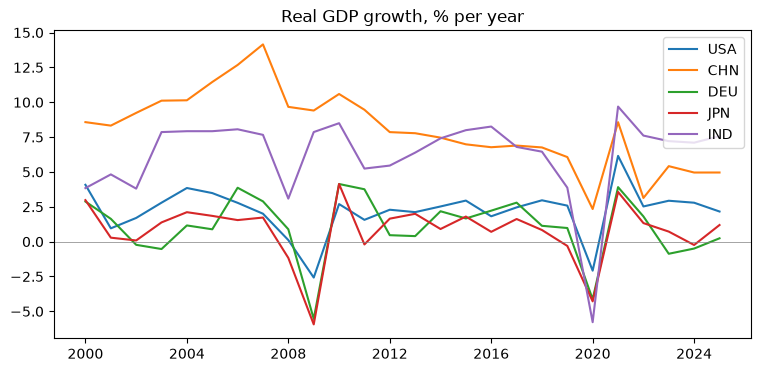

In [3]:
growth.plot(title="Real GDP growth, % per year", figsize=(9, 4)).axhline(0, color="grey", lw=0.5);

In [4]:
top = ed.top_countries("gdp-nominal", limit=10)
pd.DataFrame([r.model_dump() for r in top.data])[["iso3_code", "country_name", "value", "date"]]

,iso3_code,country_name,value,date
0,WLD,World,1.183502e+14,2025-01-01
1,OED,OECD members,7.254327e+13,2025-01-01
2,PST,Post-demographic dividend,6.737970e+13,2025-01-01
3,IBT,IDA & IBRD total,4.625140e+13,2025-01-01
4,IBD,IBRD only,4.305636e+13,2025-01-01
5,LMY,Low & middle income,4.147860e+13,2025-01-01
6,MIC,Middle income,4.083680e+13,2025-01-01
7,EAS,East Asia & Pacific,3.365698e+13,2025-01-01
8,NAC,North America,3.309924e+13,2025-01-01
9,ECS,Europe & Central Asia,3.226861e+13,2025-01-01


In [5]:
# A ready-made citation for reports and LLM answers
print(ed.cite("gdp-nominal", "DEU").citation.text)

Germany GDP nominal was $5.05 tn in 2025 (World Bank, 2025-01-01)
